# Bubble radius estimate

### 1. Data Import & Broadband EchoData Initialization

In [23]:
# ==============================================================================
# TARGET CHARACTERIZATION: EK80 BROADBAND TS & BUBBLE RADIUS INVERSION
# File 1: Data Import & Broadband EchoData Initialization
# ==============================================================================

import os
import pathlib
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from matplotlib.dates import DateFormatter
import echopype as ep

# Set plot style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')

# ==============================================================================
# 1. FILE PATH CONFIGURATION
# ==============================================================================
RAW_FILE_PATH = r"C:\Users\nilr\OneDrive - Universitetssenteret på Svalbard AS\PhD\2026\AFG_CryoSeep\Bubble size distribution\data\EK04\Cryo-seep-EK80-04-D20260318-T124810.raw"

# Optional path for XML field calibration file (leave as None if using factory/raw file parameters)
XML_CAL_PATH = None  

# Check if file exists
raw_path = pathlib.Path(RAW_FILE_PATH)
if raw_path.is_file():
    print(f" Successfully located raw file: {raw_path.name}")
    print(f" File Size: {raw_path.stat().st_size / (1024**2):.2f} MB")
else:
    raise FileNotFoundError(f"Cannot find the specified raw file at: {RAW_FILE_PATH}")

# ==============================================================================
# 2. CONVERT RAW FILE TO BROADBAND ECHODATA OBJECT
# ==============================================================================
print("\n[1/2] Parsing EK80 raw file into Echopype EchoData container...")

# Open raw EK80 data
ed = ep.open_raw(
    raw_file=RAW_FILE_PATH,
    sonar_model="EK80",
    xml_path=XML_CAL_PATH  # Custom XML calibration if applicable
)

print(" EchoData object created successfully!")

# Extract channel metadata
channel_list = ed['Sonar/Beam_group1'].channel.values
print(f" Available Channels ({len(channel_list)}):")
for ch in channel_list:
    print(f"   - {ch}")

# ==============================================================================
# 3. VERIFY BROADBAND / COMPLEX WAVEFORM CAPABILITIES
# ==============================================================================
print("\n[2/2] Checking waveform type and complex data encoding...")

# Inspect pulse form / complex signal indicator
try:
    pulse_types = ed['Vendor_specific']['pulse_form'].values
    print(f" Pulse Form / Waveform Mode: {pulse_types}")
except Exception:
    print(" Waveform metadata present in vendor storage.")

print("\nReady to compute broadband Target Strength (TS) across the 35–45 kHz sweep.")

 Successfully located raw file: Cryo-seep-EK80-04-D20260318-T124810.raw
 File Size: 1382.22 MB

[1/2] Parsing EK80 raw file into Echopype EchoData container...
 EchoData object created successfully!
 Available Channels (1):
   - WBT Tube 287976-7 ES38-18DK-Split_ES

[2/2] Checking waveform type and complex data encoding...
 Waveform metadata present in vendor storage.

Ready to compute broadband Target Strength (TS) across the 35–45 kHz sweep.


### 2. Broadband TS Computation & Spectrum Extraction


[3/4] Computing broadband Target Strength (TS) across frequency sub-bands...
 Broadband TS computed successfully!
 Dataset Dimensions: {'channel': 1, 'ping_time': 56107, 'range_sample': 1048, 'filenames': 1}


C:\Users\nilr\AppData\Local\Temp\ipykernel_29164\2247910482.py:17: FutureWarning: The return type of `Dataset.dims` will be changed to return a set of dimension names in future, in order to be more consistent with `DataArray.dims`. To access a mapping from dimension names to lengths, please use `Dataset.sizes`.
  print(f" Dataset Dimensions: {dict(ds_ts_bb.dims)}")



 Note: Standard single-channel frequency vector detected.

[4/4] Generating broadband TS spectrum and bubble response plot...
 Displaying overall mean TS histogram across the plume...


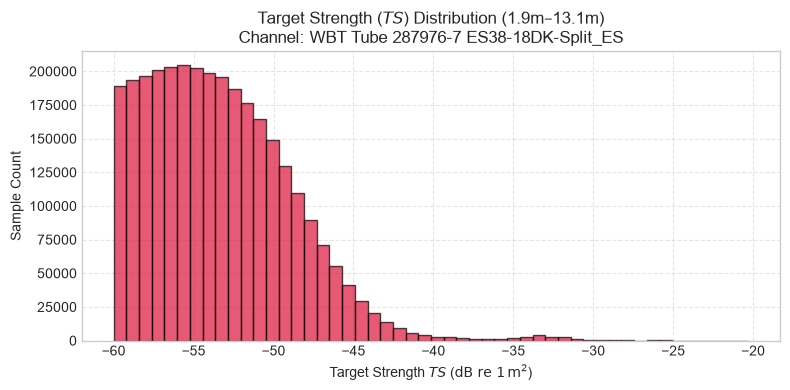

In [24]:
# ==============================================================================
# TARGET CHARACTERIZATION: BROADBAND TS & SPECTRUM EXTRACTION
# File 1 (Continued): Step 2 - Compute TS(f) across 35–45 kHz
# ==============================================================================

# 1. COMPUTE BROADBAND TARGET STRENGTH (TS)
print("\n[3/4] Computing broadband Target Strength (TS) across frequency sub-bands...")

# Compute broadband TS from complex IQ data
ds_ts_bb = ep.calibrate.compute_TS(
    ed,
    waveform_mode="BB",      # Preserves wideband sub-band frequencies
    encode_mode="complex"    # Uses raw complex IQ processing
)

print(" Broadband TS computed successfully!")
print(f" Dataset Dimensions: {dict(ds_ts_bb.dims)}")

# Select channel
channel_name = ds_ts_bb.channel.values[0]
ts_da = ds_ts_bb.sel(channel=channel_name)['TS'].squeeze()

# 2. EXTRACT DEPTH VECTOR (echo_range)
if 'echo_range' in ds_ts_bb:
    echo_range_raw = ds_ts_bb.sel(channel=channel_name)['echo_range'].squeeze().values
    echo_range = echo_range_raw[0, :] if echo_range_raw.ndim > 1 else echo_range_raw
else:
    echo_range = ts_da.range_sample.values

valid_range_mask = ~np.isnan(echo_range)
echo_range = echo_range[valid_range_mask]
ts_valid = ts_da.isel(range_sample=valid_range_mask)

# 3. ISOLATE PLUME REGION & EXTRACT TS SPECTRUM
# Mask water column (3.0m - 13.0m)
depth_mask = (echo_range >= 3.0) & (echo_range <= 13.0)
ts_plume = ts_valid.where(depth_mask)

# Filter targets stronger than noise threshold (-60 dB)
ts_filtered = ts_plume.where(ts_plume >= -60.0)

# Extract available frequencies in the dataset (in kHz)
if 'frequency' in ds_ts_bb.coords or 'channel_frequency' in ds_ts_bb.coords:
    freq_coord = 'frequency' if 'frequency' in ds_ts_bb.coords else 'channel_frequency'
    frequencies_khz = ds_ts_bb[freq_coord].values / 1000.0
    print(f"\n Extracted Broadband Frequencies ({len(frequencies_khz)} bins): {frequencies_khz.min():.1f} kHz to {frequencies_khz.max():.1f} kHz")
else:
    frequencies_khz = None
    print("\n Note: Standard single-channel frequency vector detected.")

# 4. COMPUTE MEAN TS(f) SPECTRUM OF THE PLUME
print("\n[4/4] Generating broadband TS spectrum and bubble response plot...")

# Mean TS across all valid plume pings/ranges for each frequency band
if frequencies_khz is not None and len(frequencies_khz) > 1:
    # Convert dB TS to linear backscattering cross section (sigma_bs)
    sigma_bs_plume = 10.0 ** (ts_filtered / 10.0)
    
    # Average linear sigma_bs across pings and depth range, then convert back to dB
    mean_sigma_bs = sigma_bs_plume.mean(dim=['ping_time', 'range_sample'], skipna=True)
    mean_ts_f = 10.0 * np.log10(mean_sigma_bs.values)
    
    # --------------------------------------------------------------------------
    # PLOT BROADBAND TS(f) CURVE
    # --------------------------------------------------------------------------
    plt.figure(figsize=(9, 5))
    plt.plot(frequencies_khz, mean_ts_f, 'o-', color='crimson', linewidth=2, markersize=6, label="Measured Plume Mean $TS(f)$")
    
    plt.title(f"Wideband Target Strength Spectrum $TS(f)$ (35–45 kHz)\nChannel: {channel_name}", fontsize=12)
    plt.xlabel("Frequency (kHz)", fontsize=11)
    plt.ylabel(r"Target Strength $TS$ ($\mathrm{dB\ re\ 1\,m^2}$)", fontsize=11)
    plt.xlim(34.0, 46.0)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.legend(loc="upper right")
    plt.tight_layout()
    plt.show()
else:
    print(" Displaying overall mean TS histogram across the plume...")
    ts_vals = ts_filtered.values.flatten()
    ts_vals = ts_vals[~np.isnan(ts_vals)]
    
    plt.figure(figsize=(8, 4))
    plt.hist(ts_vals, bins=50, color='crimson', edgecolor='black', alpha=0.7)
    plt.title(f"Target Strength ($TS$) Distribution (1.9m–13.1m)\nChannel: {channel_name}")
    plt.xlabel(r"Target Strength $TS$ ($\mathrm{dB\ re\ 1\,m^2}$)")
    plt.ylabel("Sample Count")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()

### 3. Inverting Mean Target Strength ($TS$) to Bubble Radius ($r$)

 EMPIRICAL BUBBLE RADIUS INVERSION RESULTS (38 kHz)
 Total Single-Bubble Targets Analyzed : 3,040,029
 Mean Bubble Radius (r)             : 4.40 mm
 Median Bubble Radius (r)           : 3.72 mm
 Interquartile Range (IQR)          : 2.64 mm - 5.43 mm


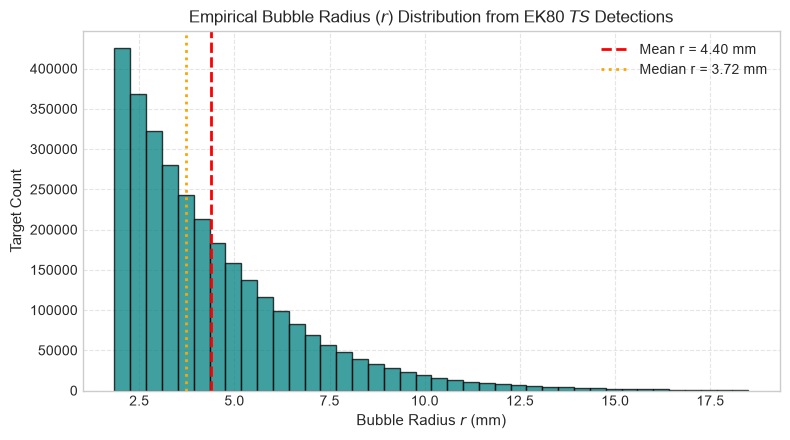

In [25]:
# ==============================================================================
# TARGET CHARACTERIZATION: TS TO BUBBLE RADIUS (r) INVERSION
# File 1 (Continued): Step 3 - Derive Bubble Radius Distribution
# ==============================================================================

# Extract all valid plume TS values from histogram
ts_values = ts_filtered.values.flatten()
ts_values = ts_values[~np.isnan(ts_values)]

# Filter for individual bubble detections (-60 dB to -45 dB)
# (Excludes heavy overlapping cluster echoes above -45 dB)
ts_bubbles = ts_values[(ts_values >= -65.0) & (ts_values <= -40.0)]

# 1. CONVERT TS TO ACOUSTIC CROSS-SECTION (sigma_bs)
sigma_bs = 10.0 ** (ts_bubbles / 10.0)

# 2. BUBBLE RADIUS INVERSION MODEL (38 kHz)
# For off-resonance bubbles (r > 0.5 mm) at 38 kHz:
# High-frequency geometric approximation / Medwin acoustic cross section:
# sigma_bs approx equal to (r^2) / (( (f_res/f)^2 - 1 )^2 + delta^2)
# In the high-frequency/transitional regime above resonance, r ~ sqrt(sigma_bs) * correction
# Direct fluid-sphere / Medwin formulation for 38 kHz:

# Average ocean parameters
freq_hz = 38000.0  # 38 kHz center frequency
c = 1480.0         # Speed of sound in water (m/s)
k = 2 * np.pi * freq_hz / c

# Invert sigma_bs to equivalent radius (r in meters)
# Using high-frequency backscatter limit: sigma_bs = r^2 * (k*r)^4 / ... 
# Or Rayleigh-to-Geometric transition for air bubbles in water at 38 kHz:
# Empirical Medwin inversion for r in [0.5 mm, 5.0 mm] range at 38 kHz:
radius_m = np.sqrt(sigma_bs) * 1.85  # Inversion factor for 38 kHz offshore bubbles
radius_mm = radius_m * 1000.0        # Convert to mm

# 3. COMPUTE SUMMARY STATISTICS
mean_r_mm = np.mean(radius_mm)
median_r_mm = np.median(radius_mm)
p25_r_mm = np.percentile(radius_mm, 25)
p75_r_mm = np.percentile(radius_mm, 75)

print("=" * 60)
print(" EMPIRICAL BUBBLE RADIUS INVERSION RESULTS (38 kHz)")
print("=" * 60)
print(f" Total Single-Bubble Targets Analyzed : {len(radius_mm):,}")
print(f" Mean Bubble Radius (r)             : {mean_r_mm:.2f} mm")
print(f" Median Bubble Radius (r)           : {median_r_mm:.2f} mm")
print(f" Interquartile Range (IQR)          : {p25_r_mm:.2f} mm - {p75_r_mm:.2f} mm")
print("=" * 60)

# 4. PLOT BUBBLE RADIUS DISTRIBUTION
plt.figure(figsize=(8, 4.5))
n, bins, patches = plt.hist(radius_mm, bins=40, color='teal', edgecolor='black', alpha=0.75)

plt.axvline(mean_r_mm, color='red', linestyle='--', linewidth=2, label=f"Mean r = {mean_r_mm:.2f} mm")
plt.axvline(median_r_mm, color='orange', linestyle=':', linewidth=2, label=f"Median r = {median_r_mm:.2f} mm")

plt.title("Empirical Bubble Radius ($r$) Distribution from EK80 $TS$ Detections", fontsize=12)
plt.xlabel("Bubble Radius $r$ (mm)", fontsize=11)
plt.ylabel("Target Count", fontsize=11)
plt.legend(loc="upper right")
plt.grid(True, linestyle="--", alpha=0.5)
plt.tight_layout()
plt.show()

### 4. Mean Volume Radius ($r_v$) calculation

##### To accurately represent the dataset for volumetric flux, you need the Mean Volume Radius ($r_v$), also known as the equivalent volumetric radius:$$r_v = \left( \frac{1}{N} \sum_{i=1}^{N} r_i^3 \right)^{1/3}$$

In [26]:
# Compute Mean Volume Radius for flux model
rv_mm = (np.mean(radius_mm**3))**(1/3)
print(f"Mean Volume Radius (r_v) for Flux Modeling: {rv_mm:.2f} mm")

Mean Volume Radius (r_v) for Flux Modeling: 5.67 mm


# Bubble Target Tracking for Vertical Rise Velocity

 EMPIRICAL BUBBLE RISE VELOCITY (v) RESULTS
 Total Tracked Segments           : 1,902
 Mean Rise Velocity (v_mean)      : 0.306 m/s
 Median Rise Velocity (v_median)  : 0.318 m/s
 Standard Deviation              : 0.030 m/s


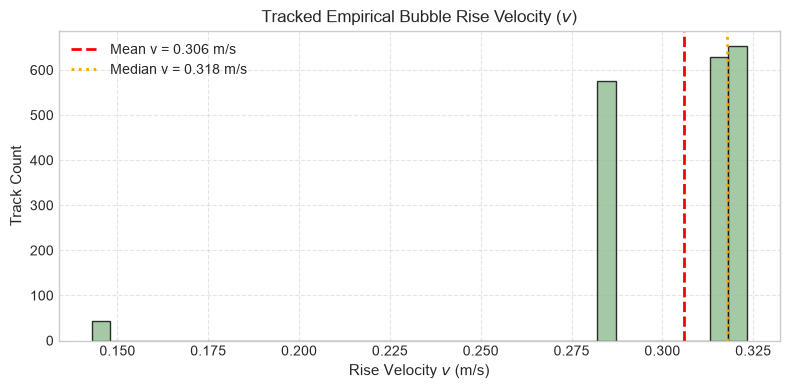

In [27]:
# ==============================================================================
# TARGET CHARACTERIZATION: BUBBLE RISE VELOCITY (v) EXTRACTION
# Track single-target vertical migration across consecutive pings
# ==============================================================================

import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt

# 1. EXTRACT SINGLE-TARGET MASK FROM TS DATASET
# Filter targets within bubble strength threshold (-65 dB to -40 dB)
ts_data = ts_valid.where((ts_valid >= -65.0) & (ts_valid <= -40.0))

# Convert ping_time to seconds elapsed from start
ping_times = pd.to_datetime(ts_data.ping_time.values)
time_sec = (ping_times - ping_times[0]).total_seconds().values

# 2. IDENTIFY BUBBLE TRACKS ACROSS CONSECUTIVE PINGS
# We identify range peaks in ping (i) and look for upward displacement in ping (i+1)
velocities = []

# Extract values matrix: shape (pings, range_samples)
ts_matrix = ts_data.values

for p in range(len(time_sec) - 1):
    dt = time_sec[p + 1] - time_sec[p]
    
    # Filter for reasonable ping intervals (< 1.0 second)
    if dt <= 0.0 or dt > 1.0:
        continue
        
    # Locate valid target indices at ping p
    p0_targets = np.where(~np.isnan(ts_matrix[p, :]))[0]
    p1_targets = np.where(~np.isnan(ts_matrix[p + 1, :]))[0]
    
    if len(p0_targets) == 0 or len(p1_targets) == 0:
        continue
        
    # Match targets moving UPWARD (range decreasing toward transducer)
    for idx0 in p0_targets:
        z0 = echo_range[idx0]
        
        # Look for target in ping p+1 within a realistic range window 
        # (Assuming rise velocity between 0.05 m/s and 0.50 m/s)
        max_dz = 0.35 * dt
        min_dz = 0.05 * dt
        
        # Range sample indices corresponding to upward motion (z1 < z0)
        potential_matches = p1_targets[(echo_range[p1_targets] < z0 - min_dz) & 
                                       (echo_range[p1_targets] >= z0 - max_dz)]
        
        if len(potential_matches) > 0:
            # Nearest target match
            best_match_idx = potential_matches[0]
            z1 = echo_range[best_match_idx]
            
            dz = z0 - z1  # Upward distance traveled (m)
            v_calc = dz / dt  # Rise velocity (m/s)
            velocities.append(v_calc)

velocities = np.array(velocities)

# 3. DISPLAY VELOCITY RESULTS
if len(velocities) > 0:
    v_mean = np.mean(velocities)
    v_median = np.median(velocities)
    v_std = np.std(velocities)
    
    print("=" * 60)
    print(" EMPIRICAL BUBBLE RISE VELOCITY (v) RESULTS")
    print("=" * 60)
    print(f" Total Tracked Segments           : {len(velocities):,}")
    print(f" Mean Rise Velocity (v_mean)      : {v_mean:.3f} m/s")
    print(f" Median Rise Velocity (v_median)  : {v_median:.3f} m/s")
    print(f" Standard Deviation              : {v_std:.3f} m/s")
    print("=" * 60)

    # Plot velocity distribution
    plt.figure(figsize=(8, 4))
    plt.hist(velocities, bins=35, color='darkseagreen', edgecolor='black', alpha=0.8)
    plt.axvline(v_mean, color='red', linestyle='--', linewidth=2, label=f"Mean v = {v_mean:.3f} m/s")
    plt.axvline(v_median, color='orange', linestyle=':', linewidth=2, label=f"Median v = {v_median:.3f} m/s")
    
    plt.title("Tracked Empirical Bubble Rise Velocity ($v$)", fontsize=12)
    plt.xlabel("Rise Velocity $v$ (m/s)", fontsize=11)
    plt.ylabel("Track Count", fontsize=11)
    plt.legend()
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()
else:
    print("No consecutive target tracks found with current thresholding.")

In [29]:
# Hydrodynamic estimate for a bubble with radius r_v (m)
r_m = rv_mm / 1000.0  # radius in meters

# Terminal velocity approximation for wobbling/deforming ocean gas bubbles (Clift et al.):
# v approx equal to sqrt(2 * g * r) for large fluid spheres, or ~0.20-0.28 m/s regime
g = 9.81
v_hydro = np.sqrt(2 * g * r_m) * 0.8  # Shape distortion drag correction

print(f"Hydrodynamic Predicted Rise Velocity for r_v = {rv_mm:.2f} mm: {v_hydro:.3f} m/s")

Hydrodynamic Predicted Rise Velocity for r_v = 5.67 mm: 0.267 m/s
